#### Create optimal model for prediciton and scale up


In [1]:
#import relevant libraries:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from scipy.stats import expon, reciprocal

import tensorflow as tf
from tensorflow.keras import layers, models


import matplotlib.dates as mdates

from skopt.space import Real, Categorical, Integer
from skopt import gp_minimize

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import numpy as np
from scipy.stats import randint, uniform, loguniform
import joblib
import xgboost as xgb

In [2]:
#preprocessing steps:

pem = pd.read_csv('../data/pem_electrolyser_dataset.csv', encoding='ISO-8859-1')

# rename columns and set all to lowercase for consistency
pem.columns = pem.columns.str.lower().str.replace(' ', '_').str.replace('(', '').str.replace(')', '')

for col in pem.select_dtypes(include='object').columns: #assign category type to categorical features
    pem[col] = pem[col].astype('category')
    
#remove cell_design_type
pem.drop('cell_design_type', axis=1, inplace=True)


# Change flow_type to categorical as well
pem['flow_type_a_number'] = pem['flow_type_a_number'].astype('category')
pem['flow_type_c_number'] = pem['flow_type_c_number'].astype('category')

# avoid multicollinearity
pem.drop('water_flow_rateml/min', inplace=True, axis=1)
pem.drop('cathode_flow_areacm2', inplace=True, axis=1)

right_skewed_columns = ['cell_voltage', 'cell_current_desa/cm2', 'electrode_areacm2', 'anode_flow_areacm2', 'pressueratm']
for col in right_skewed_columns:
    # add 1 to all, to avoid log(0) error
    pem[col + '_log'] = np.log(pem[col] + 1)
    
# drop the original columns from the dataframe, so the log columns are the only ones that remain
pem.drop(right_skewed_columns, axis=1, inplace=True)


# remove power and powerw/cm2 from the pem dataframe
pem.drop(['powerw/cm2', 'electrolysis_type'], axis=1, inplace=True)



pem.head()


,anode_type,cathode_type,anode_gde,cathode_gde,membrane_type,cathode_catalyst,anode_catalyst,catholyte,anolyte,cell_design_number,...,hydrogen_flow_rate,temprature_cellk,electrode_shape,flow_type_a_number,flow_type_c_number,cell_voltage_log,cell_current_desa/cm2_log,electrode_areacm2_log,anode_flow_areacm2_log,pressueratm_log
0,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,nafion117,MoS2,MoS2,choline_0.5M,H2SO4_0.1mol,1,...,0.100,293.15,rectangular,1,1,1.308333,0.006940,2.302585,1.924249,0.693147
1,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,nafion117,MoS2,MoS2,choline_0.5M,H2SO4_0.1mol,1,...,0.675,293.15,rectangular,1,1,1.386294,0.014678,2.302585,1.924249,0.693147
2,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,nafion117,MoS2,MoS2,choline_0.5M,H2SO4_0.1mol,1,...,1.100,293.15,rectangular,1,1,1.458615,0.026071,2.302585,1.924249,0.693147
3,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,nafion117,MoS2,MoS2,choline_0.5M,H2SO4_0.1mol,1,...,1.900,293.15,rectangular,1,1,1.526056,0.042329,2.302585,1.924249,0.693147
4,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,nafion117,MoS2,MoS2,choline_0.5M,H2SO4_0.1mol,1,...,3.000,293.15,rectangular,1,1,1.589235,0.062438,2.302585,1.924249,0.693147


#### Plot Hydrogen flow rate against power

<Axes: xlabel='powerw'>

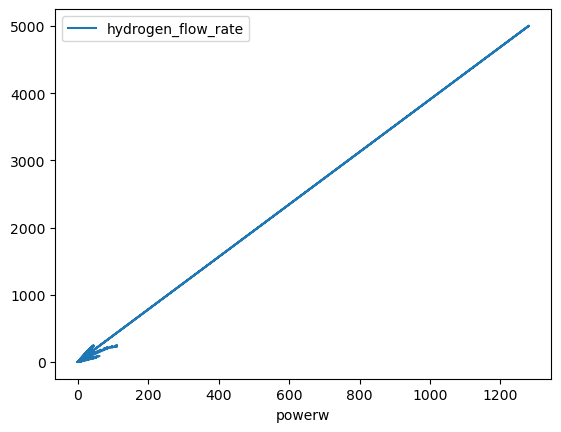

In [3]:
pem.plot(x='powerw', y='hydrogen_flow_rate', kind='line')

The relationnship between power and hydrogen flow rate appears to be linear. The data only goes to 1.2 KW. Extrapolating the data to 100 KW or a 1 MW, could be inaccurate, and represents a large extrapolation.

In [4]:
# # # filter dataset based on optimal variables:
# c1 = pem['anode_type'] == 'Titanium'
# c2 = pem['cathode_type'] == 'Titanium'
# c3 = pem['anode_gde'] == 'titanium_mesh'
# c4 = pem['cathode_gde'] == 'porous_titanium'
# c5 = pem['membrane_type'] == 'Naffion_110'
# c6 = pem['cathode_catalyst'] == '0.4_mg_Pt/cm2'
# c7 = pem['anode_catalyst'] == '2_mg_Ir/cm2+2_mg_pt/cm2'
# c8 = pem['catholyte'] == 'DI_Water'
# c9 = pem['anolyte'] == 'DI_Water'
# c10 = pem['electrode_shape'] == 'round'
# c11 = pem['flow_type_a_number'] == 29
# c12 = pem['flow_type_c_number'] == 29

# pem_filtered = pem[c1 | c2 | c3 | c4 | c5 | c6 | c7 | c8 | c9 | c10 | c11 | c12]


In [5]:
# pem_filtered

## Plot histograms of data 

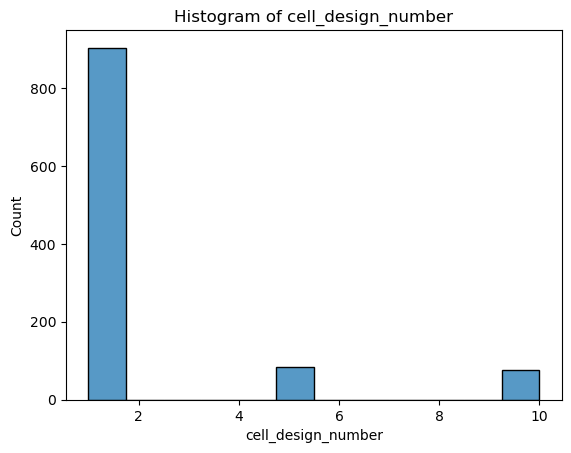

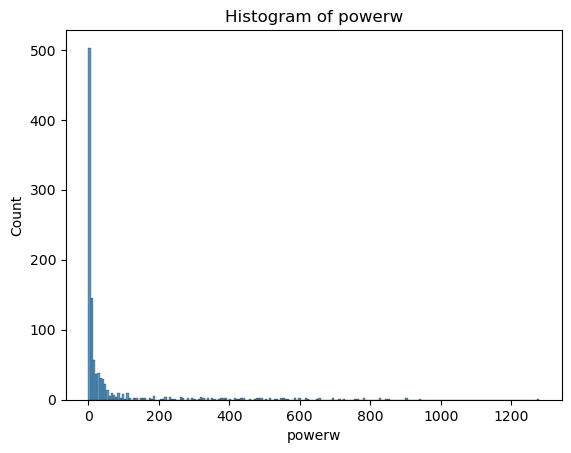

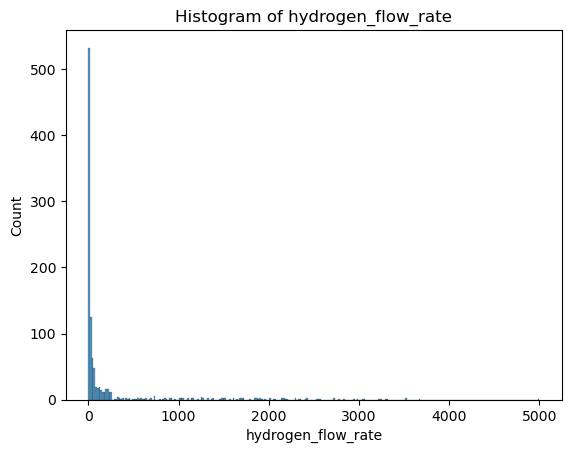

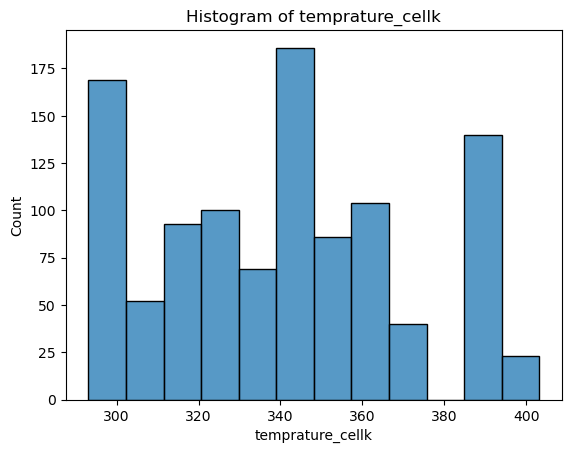

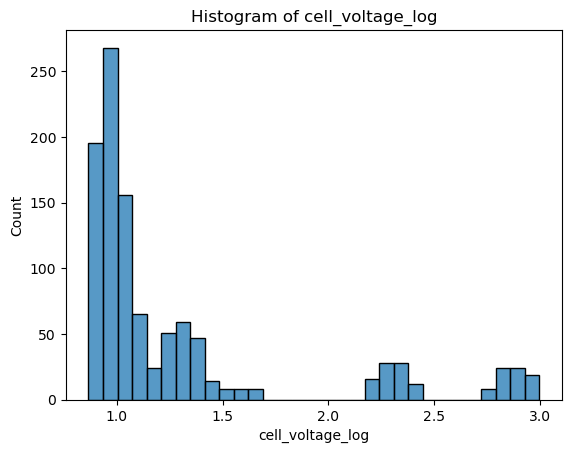

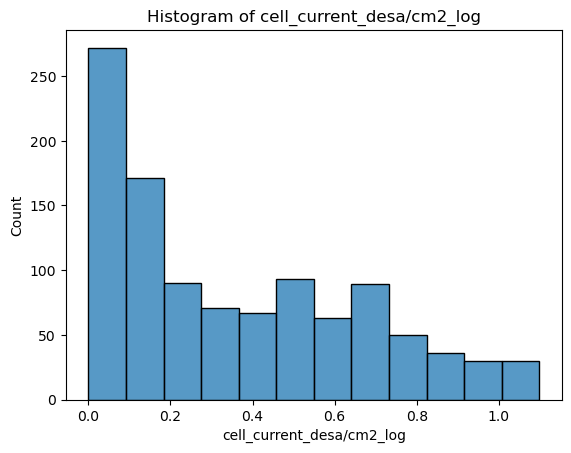

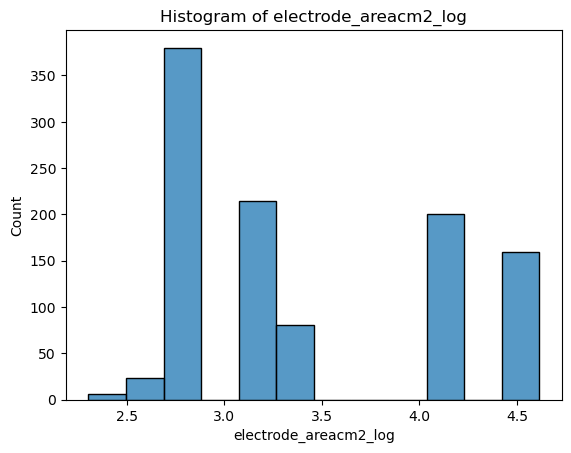

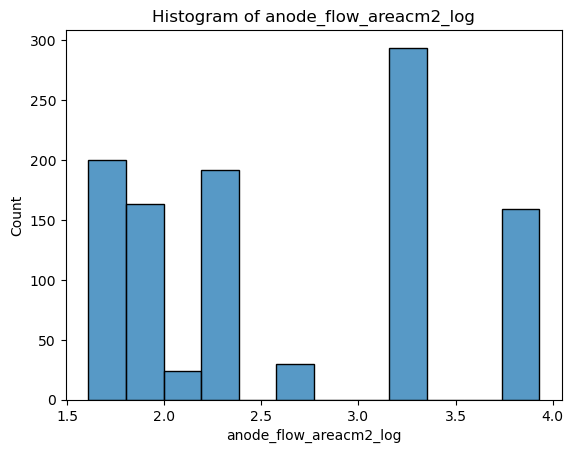

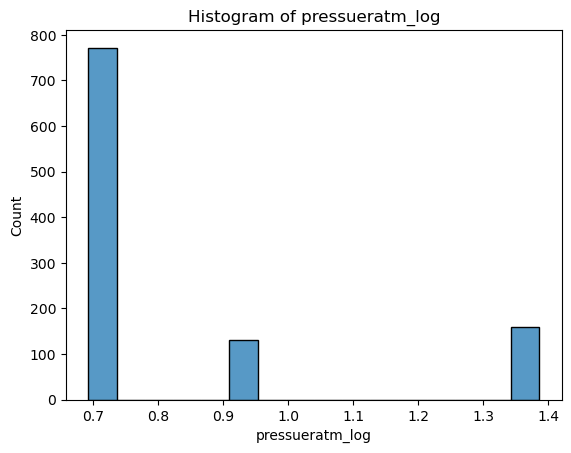

In [6]:
for col in pem.select_dtypes(include=['float64', 'int64']).columns:
    col = str(col)
    sns.histplot(pem[col])
    plt.title('Histogram of ' + col)
    plt.show()

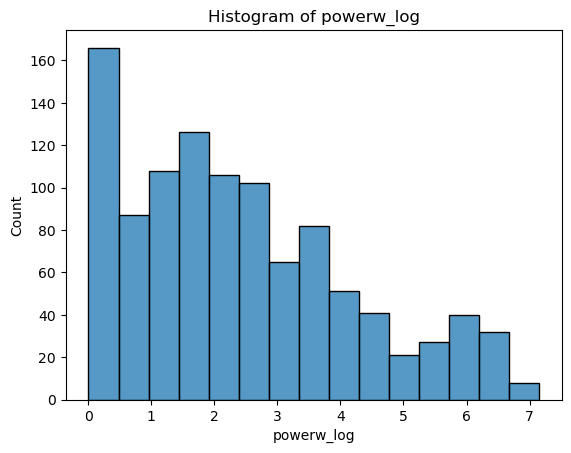

In [7]:
#logarithmic transformation for power

col = 'powerw'
pem[col + '_log'] = np.log(pem[col] + 1)

# pem.drop('powerw', axis=1, inplace=True)
# pem.drop('powerw_log', axis=1, inplace=True)
sns.histplot(pem['powerw_log'])
plt.title('Histogram of ' + 'powerw_log')
plt.show()

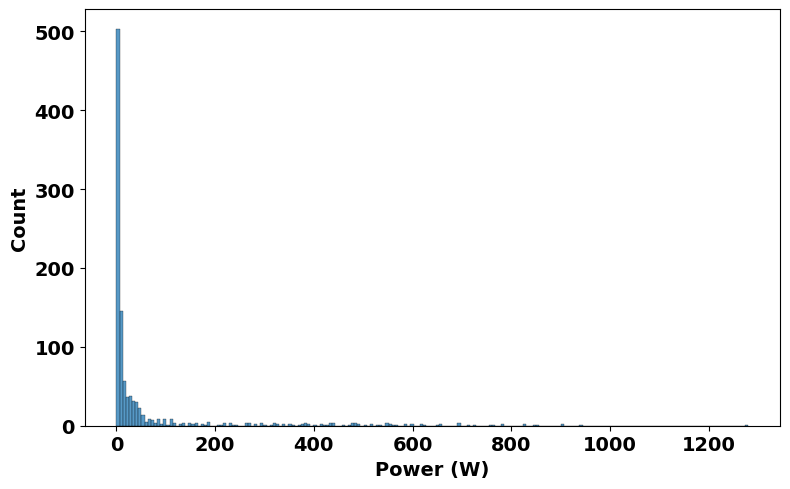

In [8]:
# histagram of power
plt.figure(figsize=(8,5))
sns.histplot(pem['powerw'])

plt.yticks(fontweight='bold', fontsize=14)
plt.xticks(fontweight='bold', fontsize=14)
plt.ylabel('Count', fontweight='bold', fontsize=14)
plt.xlabel('Power (W)', fontweight='bold', fontsize=14)
plt.savefig('power hist.png', dpi=500)

plt.tight_layout()
plt.show()

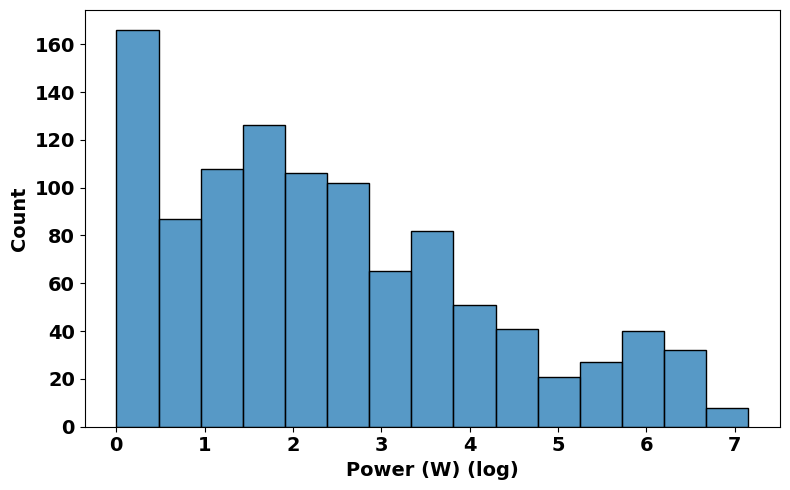

In [9]:
plt.figure(figsize=(8,5))
sns.histplot(pem['powerw_log'])

plt.yticks(fontweight='bold', fontsize=14)
plt.xticks(fontweight='bold', fontsize=14)
plt.ylabel('Count', fontweight='bold', fontsize=14)
plt.xlabel('Power (W) (log)', fontweight='bold', fontsize=14)
plt.savefig('power log hist.png', dpi=500)

plt.tight_layout()
plt.show()

In [10]:
X = pem.drop(['hydrogen_flow_rate'] , axis=1) # Assign hydrogen flow rate as target variable
Y = pem['hydrogen_flow_rate']
# initialize scaler
scaler = StandardScaler()

# cat and num columns
categorical_cols = pem.select_dtypes(include=['category']).columns
numerical_cols = X.select_dtypes(include=['float64', 'int64']).columns

#get dummmies
X=pd.get_dummies(X, categorical_cols)

#get PEM data
X[numerical_cols] = scaler.fit_transform(X[numerical_cols])

X_v = X.values
Y_v = Y.values



X_train_scaled, X_test_scaled, Y_train, Y_test = train_test_split(X_v, Y_v, test_size=0.2, random_state=42)

X.head()


# means = scaler.mean_
# std_devs = scaler.scale_

# scaling_info = pd.DataFrame({
#     'Column': numerical_cols,
#     'Mean': means,
#     'Standard Deviation': std_devs
# })

# scaling_info.head()

# scaling_info.to_csv('Scaler_mean_mapping.csv')

,cell_design_number,powerw,temprature_cellk,cell_voltage_log,cell_current_desa/cm2_log,electrode_areacm2_log,anode_flow_areacm2_log,pressueratm_log,powerw_log,anode_type_316L_stainless_steel_felt316L_stainless_steel_felt,...,flow_type_c_number_20,flow_type_c_number_21,flow_type_c_number_22,flow_type_c_number_23,flow_type_c_number_24,flow_type_c_number_25,flow_type_c_number_26,flow_type_c_number_27,flow_type_c_number_28,flow_type_c_number_29
0,-0.38609,-0.413894,-1.423709,0.028181,-1.154626,-1.693827,-0.880416,-0.532878,-1.296951,False,...,False,False,False,False,False,False,False,False,False,False
1,-0.38609,-0.412912,-1.423709,0.164631,-1.128987,-1.693827,-0.880416,-0.532878,-1.226107,False,...,False,False,False,False,False,False,False,False,False,False
2,-0.38609,-0.411266,-1.423709,0.291208,-1.091238,-1.693827,-0.880416,-0.532878,-1.124435,False,...,False,False,False,False,False,False,False,False,False,False
3,-0.38609,-0.408633,-1.423709,0.409245,-1.037367,-1.693827,-0.880416,-0.532878,-0.992473,False,...,False,False,False,False,False,False,False,False,False,False
4,-0.38609,-0.404958,-1.423709,0.519822,-0.970739,-1.693827,-0.880416,-0.532878,-0.848503,False,...,False,False,False,False,False,False,False,False,False,False


In [11]:
def performance_metrics(Y_test, y_pred):
    """Returns the performance metrics of a ml model"""
    mae = mean_absolute_error(Y_test, y_pred)
    mse = mean_squared_error(Y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(Y_test, y_pred)
    print('R2 score:', r2)
    print('MSE:',  mse)
    print('RMSE', rmse)
    print('MAE', mae)

In [12]:
print("Shape of X_train_scaled:", X_train_scaled.shape)
print("Shape of Y_train:", Y_train.shape)

Shape of X_train_scaled: (849, 110)
Shape of Y_train: (849,)


In [13]:

# instantiate rf model with the tuned hyperparameters
rf_model_tuned = RandomForestRegressor(n_estimators=322, max_depth=76, max_features='sqrt', min_samples_leaf=1, min_samples_split=3, bootstrap=False)
#fit the model
rf_model_tuned.fit(X_train_scaled, Y_train)

#use rf to find most important features
feature_importance_rf = rf_model_tuned.feature_importances_






In [14]:
y_pred = rf_model_tuned.predict(X_test_scaled)
performance_metrics(Y_test, y_pred)

R2 score: 0.9689823641634167
MSE: 11713.045350708026
RMSE 108.22682361923049
MAE 12.826524691999495


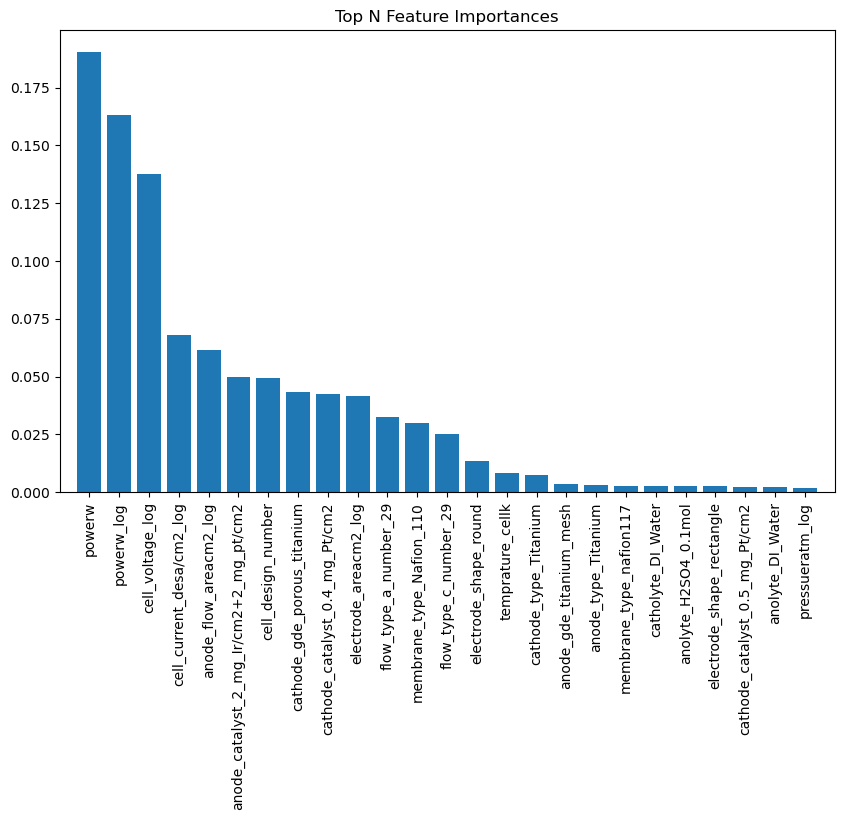

In [15]:
#plot relative importance of the features
indices = np.argsort(feature_importance_rf)[::-1]

# To plot the top N most important features
N = 25
plt.figure(figsize=(10, 6))
plt.title("Top N Feature Importances")
plt.bar(range(N), feature_importance_rf[indices[:N]], align="center")
plt.xticks(range(N), X.columns[indices[:N]], rotation=90)
plt.xlim([-1, N])
plt.show()

In [16]:
row = X.iloc[1:2]
row

,cell_design_number,powerw,temprature_cellk,cell_voltage_log,cell_current_desa/cm2_log,electrode_areacm2_log,anode_flow_areacm2_log,pressueratm_log,powerw_log,anode_type_316L_stainless_steel_felt316L_stainless_steel_felt,...,flow_type_c_number_20,flow_type_c_number_21,flow_type_c_number_22,flow_type_c_number_23,flow_type_c_number_24,flow_type_c_number_25,flow_type_c_number_26,flow_type_c_number_27,flow_type_c_number_28,flow_type_c_number_29
1,-0.38609,-0.412912,-1.423709,0.164631,-1.128987,-1.693827,-0.880416,-0.532878,-1.226107,False,...,False,False,False,False,False,False,False,False,False,False


In [17]:
dummy_df = X.select_dtypes(include='bool')
dummy_list = dummy_df.columns.tolist()

In [18]:
print(dummy_list)

for dummy in dummy_list:
    row[dummy] = False

row.head()

['anode_type_316L_stainless_steel_felt316L_stainless_steel_felt', 'anode_type_316L_stainless_steel_felt317L_stainless_steel_felt', 'anode_type_Ni_foam', 'anode_type_Titanium', 'anode_type_carbon_plate', 'anode_type_silver_coated_3D_printed_components_fabricate_from_polypropylene', 'cathode_type_316L_stainless_steel_felt316L_stainless_steel_felt', 'cathode_type_316L_stainless_steel_felt317L_stainless_steel_felt', 'cathode_type_Titanium', 'cathode_type_carbon_plate', 'cathode_type_silver_coated_3D_printed_components_fabricate_from_polypropylene', 'anode_gde_Ni_foam', 'anode_gde_Titanium', 'anode_gde_a_double_layer_felt', 'anode_gde_a_single_layer_felt', 'anode_gde_porous_carbon_paper', 'anode_gde_titanium_felt', 'anode_gde_titanium_mesh', 'cathode_gde_ a_wet_proofed_non-woven_carbon_cloth', 'cathode_gde_Ni_foam', 'cathode_gde_carbon_paper', 'cathode_gde_porous_carbon_paper', 'cathode_gde_porous_titanium', 'membrane_type_Aquivion\x99_E79-05S_50_?m_(Solvay_Solexis)', 'membrane_type_Nafion_

C:\Users\hasee\AppData\Local\Temp\ipykernel_37056\597224005.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  row[dummy] = False


,cell_design_number,powerw,temprature_cellk,cell_voltage_log,cell_current_desa/cm2_log,electrode_areacm2_log,anode_flow_areacm2_log,pressueratm_log,powerw_log,anode_type_316L_stainless_steel_felt316L_stainless_steel_felt,...,flow_type_c_number_20,flow_type_c_number_21,flow_type_c_number_22,flow_type_c_number_23,flow_type_c_number_24,flow_type_c_number_25,flow_type_c_number_26,flow_type_c_number_27,flow_type_c_number_28,flow_type_c_number_29
1,-0.38609,-0.412912,-1.423709,0.164631,-1.128987,-1.693827,-0.880416,-0.532878,-1.226107,False,...,False,False,False,False,False,False,False,False,False,False


In [19]:
# set up the optimal configuration
row['anode_type_Titanium'] = True
row['cathode_type_Titanium'] = True
row['anode_gde_titanium_mesh'] = True
row['cathode_gde_porous_titanium'] = True
row['membrane_type_Nafion_110'] = True
row['cathode_catalyst_0.4_mg_Pt/cm2'] = True
row['anode_catalyst_2_mg_Ir/cm2+2_mg_pt/cm2'] = True
row['catholyte_DI_Water'] = True
row['anolyte_DI_Water'] = True
row['electrode_shape_round'] = True
row['flow_type_a_number_29'] = True
row['flow_type_c_number_29'] = True

C:\Users\hasee\AppData\Local\Temp\ipykernel_37056\807858836.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  row['anode_type_Titanium'] = True
C:\Users\hasee\AppData\Local\Temp\ipykernel_37056\807858836.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  row['cathode_type_Titanium'] = True
C:\Users\hasee\AppData\Local\Temp\ipykernel_37056\807858836.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See

In [20]:
# function for scaling the data

mappings = pd.read_csv('Scaler_mean_mapping.csv')

def scaler_func(x, feature):
    feature_row = mappings[mappings['Column'] == feature]
    if not feature_row.empty:
        mean = feature_row['Mean'].values[0]
        std_dev = feature_row['Standard Deviation'].values[0]
    # scale data
        scaled_data = (x - mean) / std_dev
        return scaled_data
    else:
        raise ValueError(f"Feature '{feature}' not found in scaler mappings.")


row.head()

def scaler_func_log(x, feature):
    x = np.log(x + 1)
    
    feature_row = mappings[mappings['Column'] == feature]
    if not feature_row.empty:
        mean = feature_row['Mean'].values[0]
        std_dev = feature_row['Standard Deviation'].values[0]
    # scale data
        scaled_data = (x - mean) / std_dev
        return scaled_data
    else:
        raise ValueError(f"Feature '{feature}' not found in scaler mappings.")
    

In [21]:
# input optimal numerical parameters into the model
row['cell_design_number'] = scaler_func(10, 'cell_design_number')
row['temprature_cellk'] = scaler_func(337.03, 'temprature_cellk')
row['cell_current_desa/cm2_log'] = scaler_func_log(2, 'cell_current_desa/cm2_log')
row['electrode_areacm2_log'] = scaler_func_log(80.86, 'electrode_areacm2_log')
row['anode_flow_areacm2_log'] = scaler_func_log(50, 'anode_flow_areacm2_log')
row['pressueratm_log'] = scaler_func_log(1, 'pressueratm_log')
# row['powerw_log'] = scaler_func_log(1280, 'powerw_log')

C:\Users\hasee\AppData\Local\Temp\ipykernel_37056\1827035460.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  row['cell_design_number'] = scaler_func(10, 'cell_design_number')
C:\Users\hasee\AppData\Local\Temp\ipykernel_37056\1827035460.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  row['temprature_cellk'] = scaler_func(337.03, 'temprature_cellk')
C:\Users\hasee\AppData\Local\Temp\ipykernel_37056\1827035460.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFr

In [22]:
row.head()

,cell_design_number,powerw,temprature_cellk,cell_voltage_log,cell_current_desa/cm2_log,electrode_areacm2_log,anode_flow_areacm2_log,pressueratm_log,powerw_log,anode_type_316L_stainless_steel_felt316L_stainless_steel_felt,...,flow_type_c_number_20,flow_type_c_number_21,flow_type_c_number_22,flow_type_c_number_23,flow_type_c_number_24,flow_type_c_number_25,flow_type_c_number_26,flow_type_c_number_27,flow_type_c_number_28,flow_type_c_number_29
1,3.264008,-0.412912,-0.083732,0.164631,2.462527,1.366346,1.59083,-0.532878,-1.226107,False,...,False,False,False,False,False,False,False,False,False,True


In [23]:
prediction = rf_model_tuned.predict(row)
print(prediction)

[699.72337526]


C:\ProgramData\Anaconda3\lib\site-packages\sklearn\base.py:457: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(


### Now need to explore the dynamic power input into the model

Start by exploring the wind power dataset

In [24]:
# import wind power dataset
wind_df = pd.read_csv("../data/wind_turbine_scada_2018.csv")
wind_df

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
0,01 01 2018 00:00,380.047791,5.311336,416.328908,259.994904
1,01 01 2018 00:10,453.769196,5.672167,519.917511,268.641113
2,01 01 2018 00:20,306.376587,5.216037,390.900016,272.564789
3,01 01 2018 00:30,419.645905,5.659674,516.127569,271.258087
4,01 01 2018 00:40,380.650696,5.577941,491.702972,265.674286
...,...,...,...,...,...
50525,31 12 2018 23:10,2963.980957,11.404030,3397.190793,80.502724
50526,31 12 2018 23:20,1684.353027,7.332648,1173.055771,84.062599
50527,31 12 2018 23:30,2201.106934,8.435358,1788.284755,84.742500
50528,31 12 2018 23:40,2515.694092,9.421366,2418.382503,84.297913


In [25]:
wind_df.describe() #describe dataset

,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
count,50530.000000,50530.000000,50530.000000,50530.000000
mean,1307.684332,7.557952,1492.175463,123.687559
std,1312.459242,4.227166,1368.018238,93.443736
min,-2.471405,0.000000,0.000000,0.000000
25%,50.677890,4.201395,161.328167,49.315437
50%,825.838074,7.104594,1063.776283,73.712978
75%,2482.507568,10.300020,2964.972462,201.696720
max,3618.732910,25.206011,3600.000000,359.997589


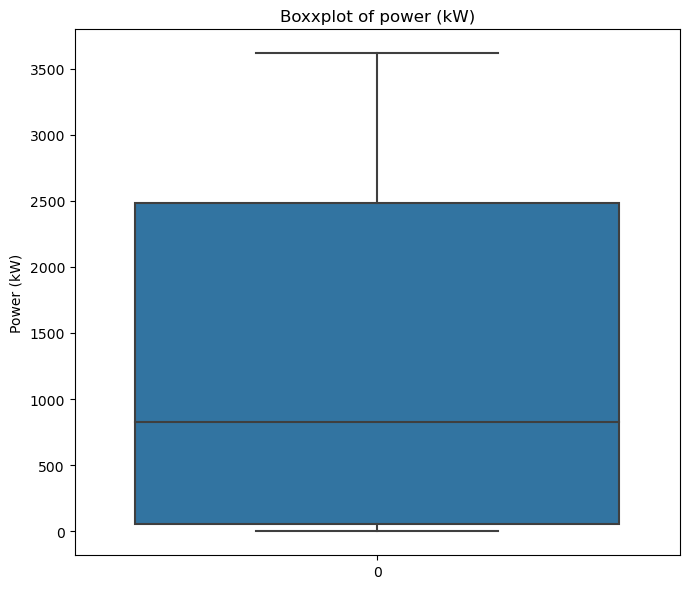

In [26]:
plt.figure(figsize=(7, 6))  # Sets the figure size
 # Specify the column for which to create the boxplot
sns.boxplot(data=wind_df['LV ActivePower (kW)'])
plt.title('Boxxplot of power (kW)')  # Adds a title to the boxplot
plt.ylabel('Power (kW)')  # Adds a y-label
 # Adds a grid for better readability
plt.tight_layout()
plt.show()  # Displays the plot

50,530 datapoints

In [27]:
# slice data to generate a new dataframe with just Active power ,and remove the negative values ( could throw off model)
new_df = wind_df[['Date/Time', 'LV ActivePower (kW)']].copy()
#remove all negative values 
new_df = new_df[new_df["LV ActivePower (kW)"] >= 0]

new_df.reset_index(drop=True, inplace=True)

new_df.head()


# 50473 values, so from 0 - 50472`

,Date/Time,LV ActivePower (kW)
0,01 01 2018 00:00,380.047791
1,01 01 2018 00:10,453.769196
2,01 01 2018 00:20,306.376587
3,01 01 2018 00:30,419.645905
4,01 01 2018 00:40,380.650696


In [28]:
new_df['Date/Time'] = pd.to_datetime(new_df['Date/Time'], format='%d %m %Y %H:%M') # new_df to datetime

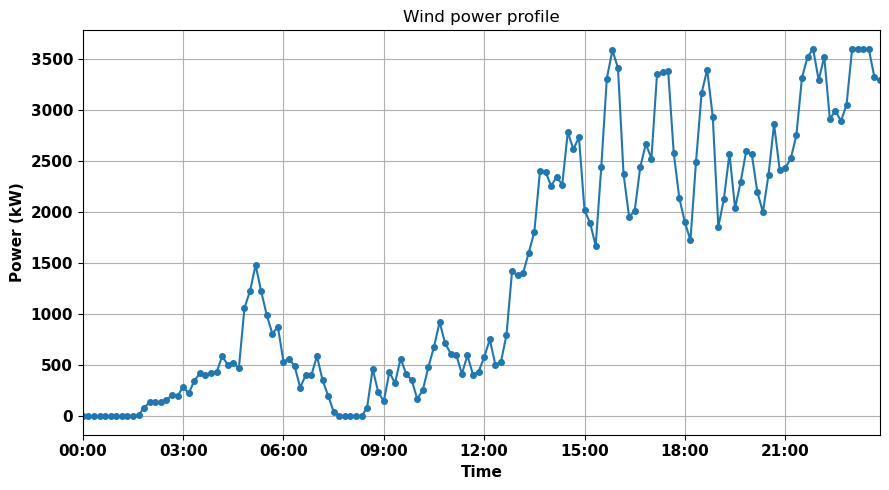

In [29]:
# plot hydrogen production for january the 1st
feb_fourth_power = new_df[new_df['Date/Time'].dt.date == pd.to_datetime('2018-02-07').date()]


plt.figure(figsize=(9, 5))
graph = plt.plot(feb_fourth_power['Date/Time'], feb_fourth_power['LV ActivePower (kW)'], marker='o', markersize=4)
plt.title('Wind power profile')
plt.xlabel('Time', fontweight='bold', fontsize=11)
plt.ylabel('Power (kW)', fontweight='bold', fontsize=11)
plt.grid(True)


# Format the x-axis ticks to show hours and minutes and set at 3-hour intervals
hours_fmt = mdates.DateFormatter('%H:%M')
plt.gca().xaxis.set_major_formatter(hours_fmt)
plt.gca().xaxis.set_major_locator(mdates.HourLocator(interval=3))

# Set the x-axis limits to the min and max of your data
plt.xlim(feb_fourth_power['Date/Time'].min(), feb_fourth_power['Date/Time'].max())
plt.xticks(fontweight='bold', fontsize=11)
plt.yticks(fontweight='bold', fontsize=11)

plt.tight_layout()  # Adjust the plot to ensure everything fits without overlapping
plt.show()


In [30]:
# Sum the power column 
new_df_1 = new_df.copy()

# Copy the DataFrame to ensure original data is not modified
new_df_1 = new_df.copy()
new_df_1.head()


,Date/Time,LV ActivePower (kW)
0,2018-01-01 00:00:00,380.047791
1,2018-01-01 00:10:00,453.769196
2,2018-01-01 00:20:00,306.376587
3,2018-01-01 00:30:00,419.645905
4,2018-01-01 00:40:00,380.650696


In [31]:

# new_df.set_index('Date/Time', inplace=True)

daily_power = new_df_1.groupby(new_df_1['Date/Time'].dt.date)['LV ActivePower (kW)'].sum().reset_index(name='Total Power (kW)')

daily_power['Date/Time'] = pd.to_datetime(daily_power['Date/Time'])

# Extract year and month for grouping
daily_power['YearMonth'] = daily_power['Date/Time'].dt.to_period('M')

# Group by 'YearMonth' if you need monthly sums or counts
monthly_power = daily_power.groupby('YearMonth')['Total Power (kW)'].sum().reset_index(name='Monthly Power (kW)')

# Determine the number of unique year-month combinations for subplot dimensions
unique_months = daily_power['YearMonth'].nunique()


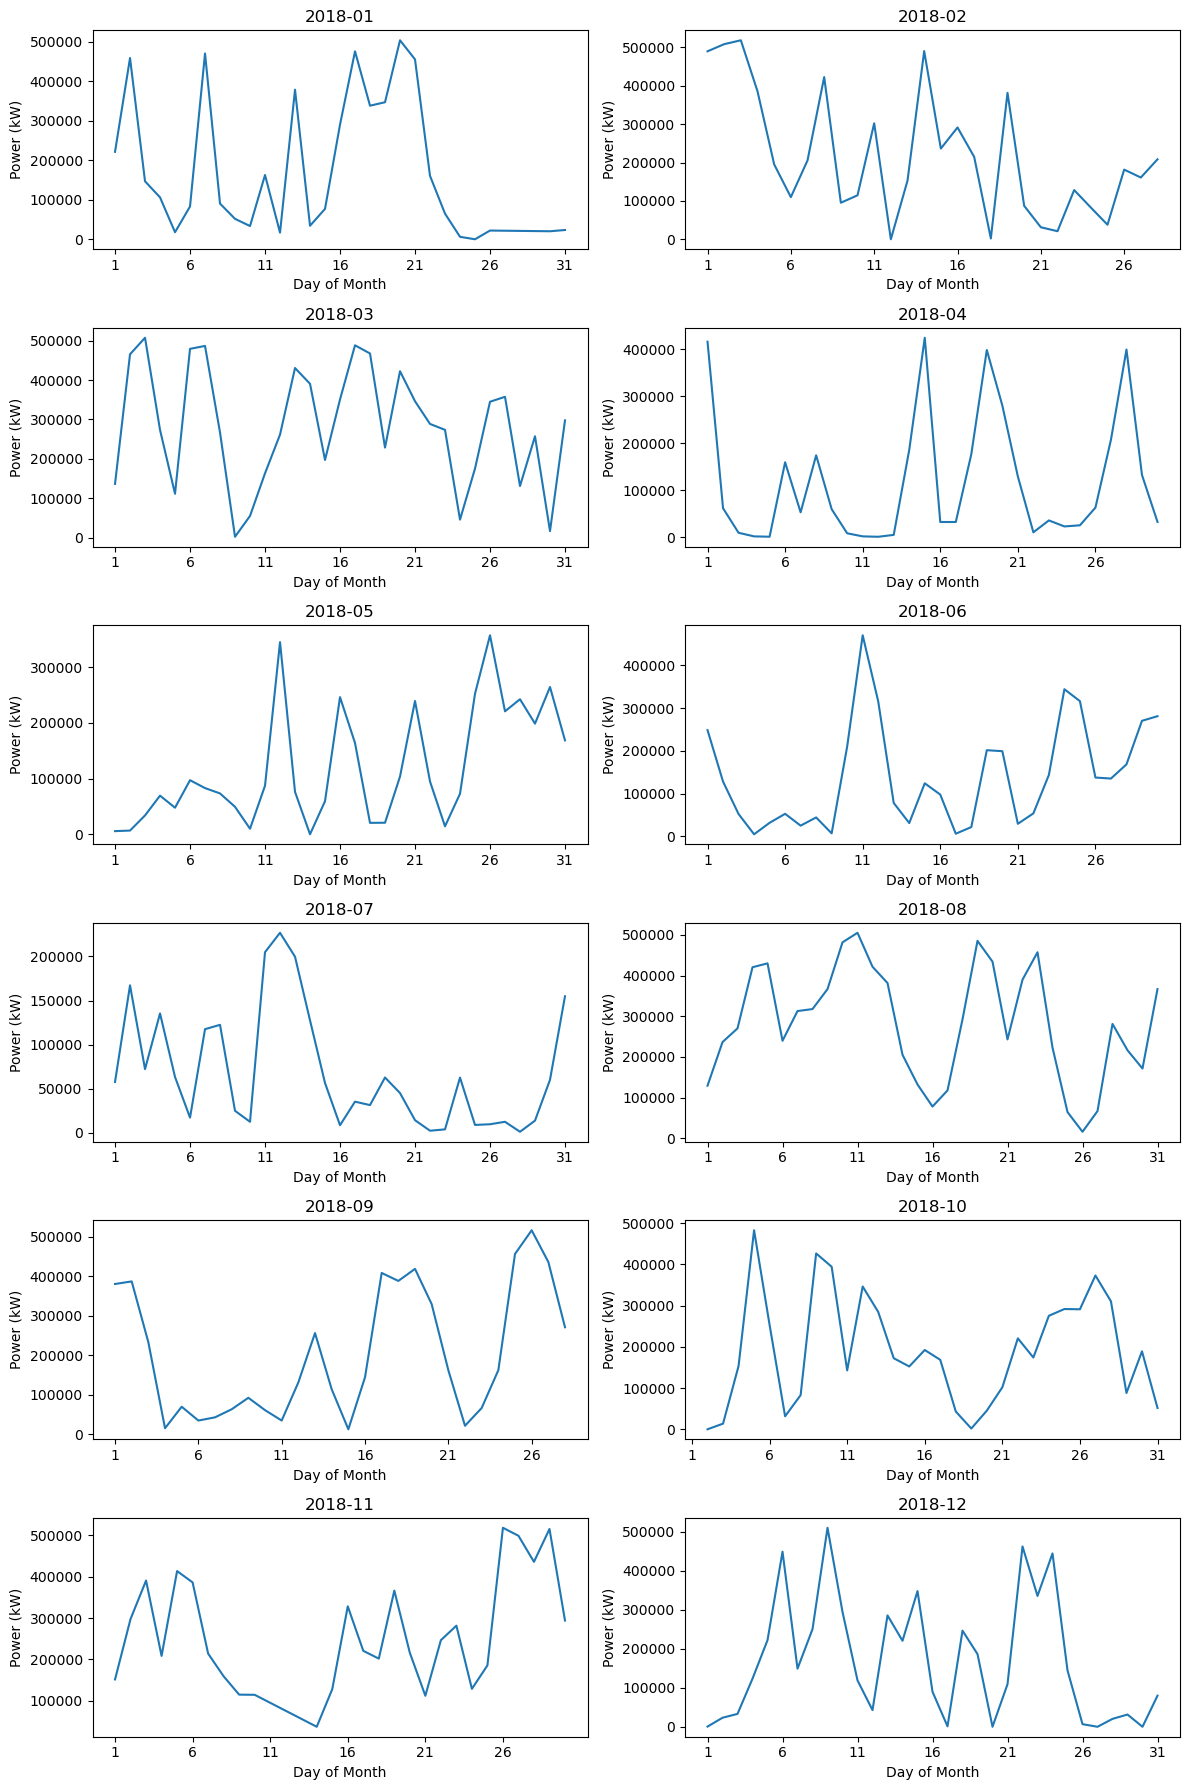

In [32]:

# Setup the plot grid
cols = 2  # Number of columns in the plot grid
rows = unique_months // cols + (unique_months % cols > 0)  # Calculate rows, ensuring all months are included



plt.figure(figsize=(12, rows*3))  # Adjust overall figure size dynamically based on the number of rows
gs = GridSpec(rows, cols)

for i, (month, group) in enumerate(daily_power.groupby('YearMonth')):
    ax = plt.subplot(gs[i])
    group['DayOfMonth'] = group['Date/Time'].dt.day
    group.plot(x='DayOfMonth', y='Total Power (kW)', ax=ax, legend=None)
    ax.set_title(str(month))
    ax.set_xlabel('Day of Month')
    ax.set_ylabel('Power (kW)')
    ax.set_xticks(range(1, group['DayOfMonth'].max() + 1, 5))# Setting x-ticks to cover each day of the month
    ax.tick_params(axis='x')

plt.tight_layout()
# plt.savefig('subplot.pdf', dpi=1000)
plt.show()


In [33]:
new_df.describe()

,Date/Time,LV ActivePower (kW)
count,50473,50473.000000
mean,2018-07-01 20:58:44.799397632,1309.161489
min,2018-01-01 00:00:00,0.000000
25%,2018-04-03 07:20:00,52.740540
50%,2018-06-30 17:10:00,828.006714
75%,2018-09-26 19:20:00,2484.364014
max,2018-12-31 23:50:00,3618.732910
std,NaN,1312.463427


In [34]:
row_change = row
row_change.head()

,cell_design_number,powerw,temprature_cellk,cell_voltage_log,cell_current_desa/cm2_log,electrode_areacm2_log,anode_flow_areacm2_log,pressueratm_log,powerw_log,anode_type_316L_stainless_steel_felt316L_stainless_steel_felt,...,flow_type_c_number_20,flow_type_c_number_21,flow_type_c_number_22,flow_type_c_number_23,flow_type_c_number_24,flow_type_c_number_25,flow_type_c_number_26,flow_type_c_number_27,flow_type_c_number_28,flow_type_c_number_29
1,3.264008,-0.412912,-0.083732,0.164631,2.462527,1.366346,1.59083,-0.532878,-1.226107,False,...,False,False,False,False,False,False,False,False,False,True


In [35]:


# %%time
# power_test = [100, 200, 300]
# hydrogen = []
# for i in power_test:
#     power_log = scaler_func_log(i, 'powerw_log')
#     row_change['powerw_log'] = power_log
#     result = (rf_model_tuned.predict(row))
#     hydrogen.append(result[0])
# print(hydrogen)

In [36]:
# # generate a list for hydrogen flow rate
# hydrogen_result = []
# for i in new_df['LV ActivePower (kW)']:
#     power = i * 10 ** 3
#     quotient, remainder = divmod(power, 1280)
#     hydrogen = rf_model_tuned.predict(row)
#     hydrogen = hydrogen[0] * 10 * quotient # as reading every 10 minutes and quotient will be the number of electrolysers at full power
#     power_log_remainder = scaler_func_log(remainder, 'powerw_log')
#     row_change['powerw_log'] = power_log_remainder
#     hydrogen_1 = rf_model_tuned.predict(row_change)
#     hydrogen_1 = hydrogen_1[0] * 10 # as reading every 10 minutes 
#     hydrogen_result.append(hydrogen + hydrogen_1) # total hydrogen produced in ml


    
    


In [37]:
# sort out hydrogen ml to kg conversion
hydrogen_result_df = pd.read_csv('../results/hydrogen_result.csv')
hydrogen_result_df.head()
hydrogen_result_df['Hydrogen ml'] = hydrogen_result_df['Hydrogen ml'] * 8.2e-8
hydrogen_result_df = hydrogen_result_df.rename(columns={'Hydrogen ml': 'Hydrogen (kg)'})
hydrogen_result_df.head()

,Unnamed: 0,Hydrogen (kg)
0,0,0.056095
1,1,0.065854
2,2,0.046647
3,3,0.063110
4,4,0.057622


In [38]:
#combine the dataset with the new_df dataset
new_df['Hydrogen (kg)'] = hydrogen_result_df['Hydrogen (kg)']
new_df.head()

,Date/Time,LV ActivePower (kW),Hydrogen (kg)
0,2018-01-01 00:00:00,380.047791,0.056095
1,2018-01-01 00:10:00,453.769196,0.065854
2,2018-01-01 00:20:00,306.376587,0.046647
3,2018-01-01 00:30:00,419.645905,0.063110
4,2018-01-01 00:40:00,380.650696,0.057622


In [39]:
# create a new data frame called days_df, and combine the hydrogen production data based on days
days_df = new_df
# days_df.to_csv('days_df.csv')

# Convert the 'Date/Time' column to datetime
days_df['Date/Time'] = pd.to_datetime(days_df['Date/Time'], format='%d %m %Y %H:%M')

# Sum the 'Hydrogen (kg)' column, grouping by the day and create a new df daily_hydrogen
daily_hydrogen = days_df.groupby(days_df['Date/Time'].dt.date)['Hydrogen (kg)'].sum().reset_index(name='Total Hydrogen (kg)')




daily_hydrogen.head()
# daily_hydrogen.to_csv('daily_hydrogen.csv')



,Date/Time,Total Hydrogen (kg)
0,2018-01-01,32.135735
1,2018-01-02,66.368950
2,2018-01-03,21.343923
3,2018-01-04,15.461498
4,2018-01-05,2.664037


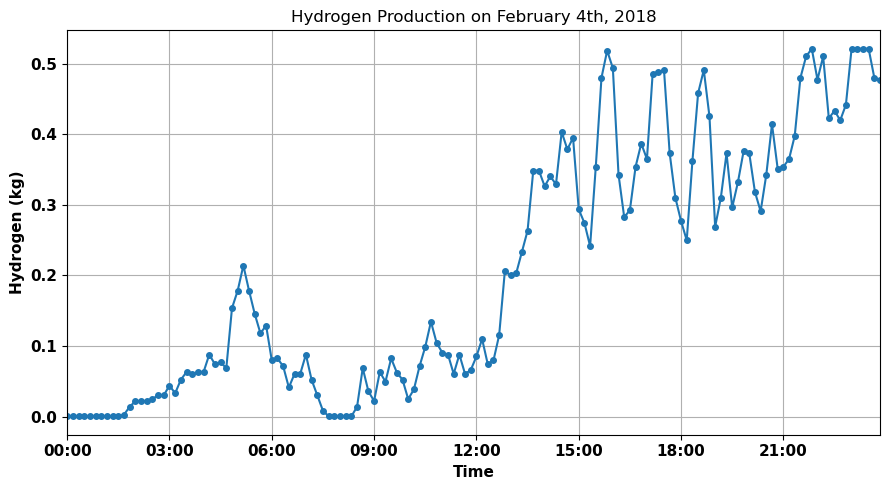

In [40]:
# plot hydrogen production for january the 1st
feb_fourth = days_df[days_df['Date/Time'].dt.date == pd.to_datetime('2018-02-07').date()]


plt.figure(figsize=(9, 5))
graph = plt.plot(feb_fourth['Date/Time'], feb_fourth['Hydrogen (kg)'], marker='o', markersize=4)
plt.title('Hydrogen Production on February 4th, 2018')
plt.xlabel('Time', fontweight='bold', fontsize=11)
plt.ylabel('Hydrogen (kg)', fontweight='bold', fontsize=11)
plt.grid(True)


# Format the x-axis ticks to show hours and minutes and set at 3-hour intervals
hours_fmt = mdates.DateFormatter('%H:%M')
plt.gca().xaxis.set_major_formatter(hours_fmt)
plt.gca().xaxis.set_major_locator(mdates.HourLocator(interval=3))

# Set the x-axis limits to the min and max of your data
plt.xlim(feb_fourth['Date/Time'].min(), feb_fourth['Date/Time'].max())
plt.xticks(fontweight='bold', fontsize=11)
plt.yticks(fontweight='bold', fontsize=11)

plt.tight_layout()  # Adjust the plot to ensure everything fits without overlapping
plt.show()


In [41]:
daily_hydrogen['Date/Time'] = pd.to_datetime(daily_hydrogen['Date/Time'])
daily_hydrogen.set_index('Date/Time', inplace=True)

In [42]:
#set datetime index
# Convert "Date/Time" to datetime format and set it as index


# Extract year and month for grouping
daily_hydrogen['YearMonth'] = daily_hydrogen.index.to_period('M')

# Determine the number of unique year-month combinations for subplot dimensions
unique_months = daily_hydrogen['YearMonth'].nunique()


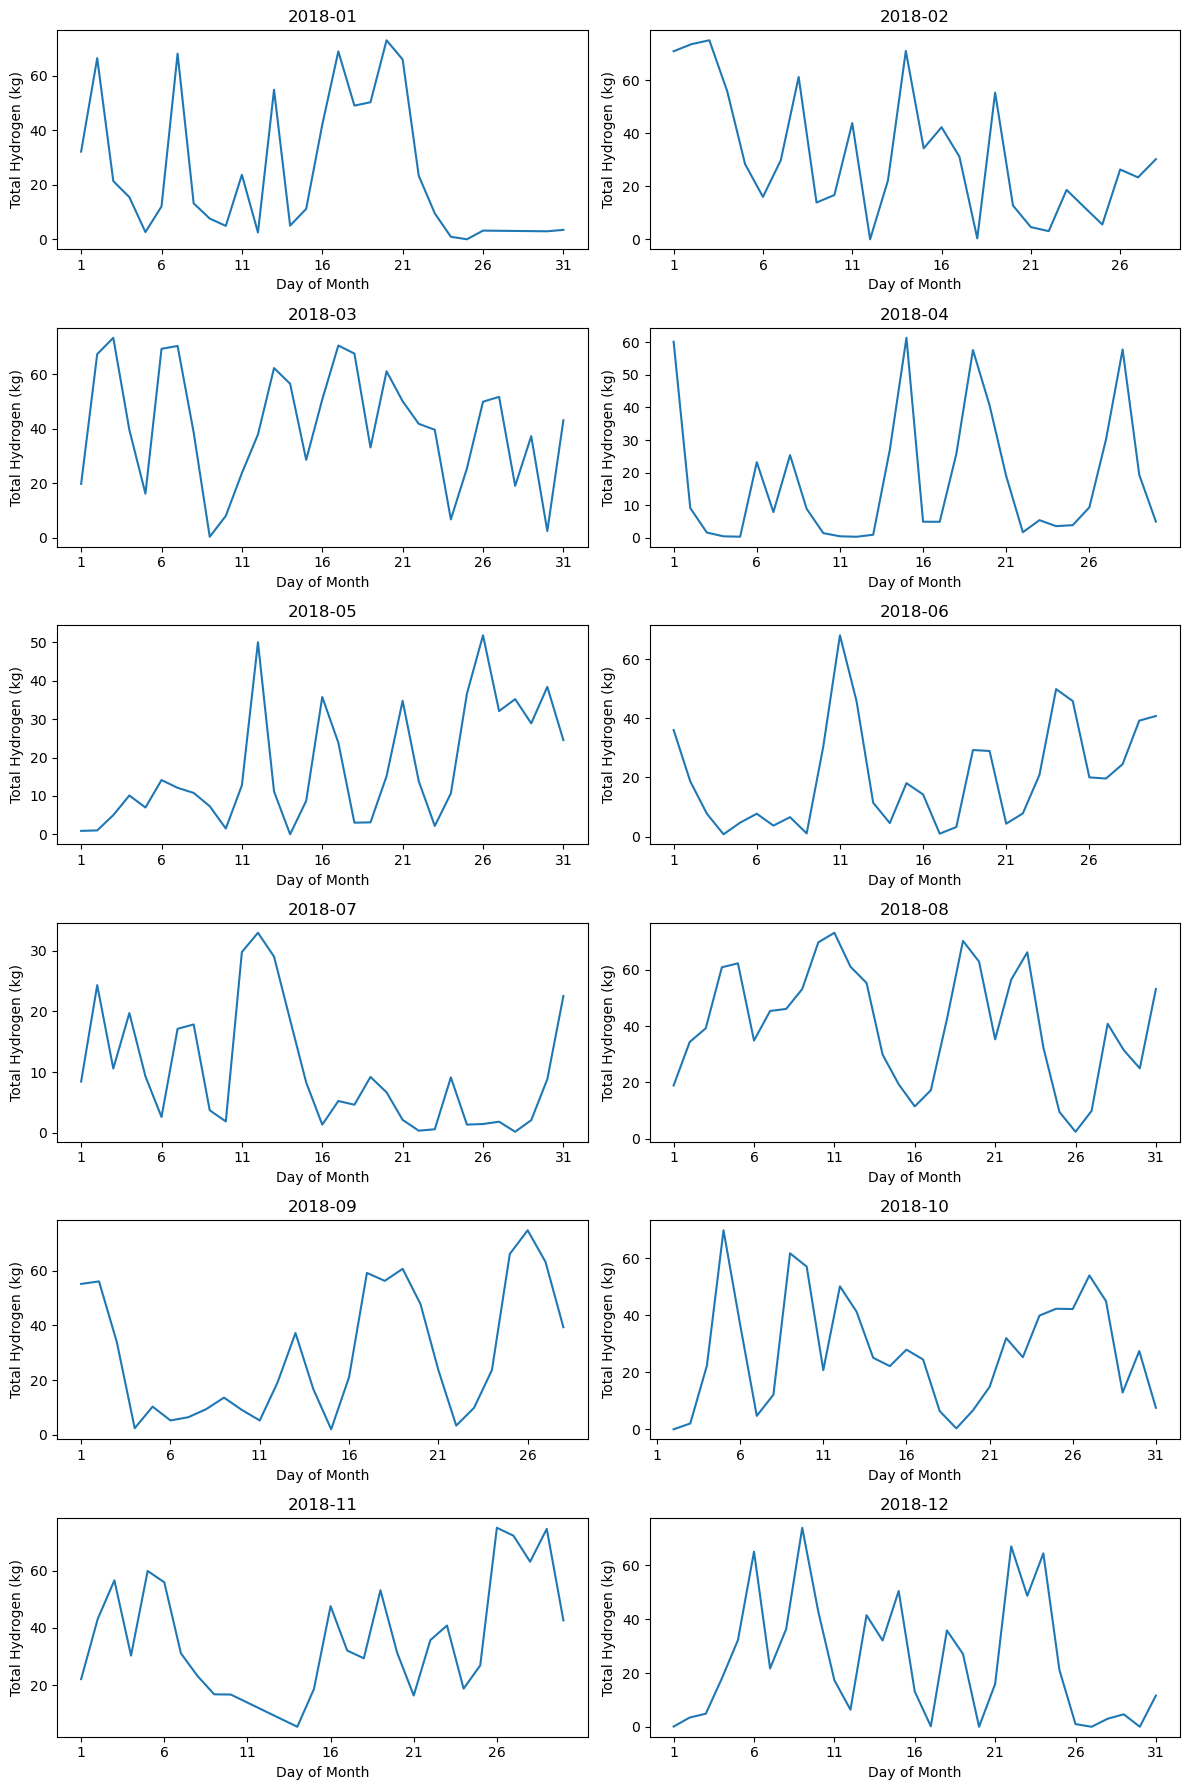

In [50]:


# Setup the plot grid
cols = 2  # Number of columns in the plot grid
rows = unique_months // cols + (unique_months % cols > 0)  # Calculate rows, ensuring all months are included

plt.figure(figsize=(12, rows*3))  # Adjust overall figure size dynamically based on the number of rows
gs = GridSpec(rows, cols)

for i, (month, group) in enumerate(daily_hydrogen.groupby('YearMonth')):
    ax = plt.subplot(gs[i])
    ax = plt.subplot(gs[i])
    group['DayOfMonth'] = group.index.day
    group.plot(x='DayOfMonth', y='Total Hydrogen (kg)', ax=ax, legend=None)
    ax.set_title(str(month))
    ax.set_xlabel('Day of Month')
    ax.set_ylabel('Total Hydrogen (kg)')
    ax.set_xticks(range(1, group['DayOfMonth'].max() + 1, 5))# Setting x-ticks to cover each day of the month
    ax.tick_params(axis='x')




  # ax = plt.subplot(gs[i])
  #   group['DayOfMonth'] = group['Date/Time'].dt.day
  #   group.plot(x='DayOfMonth', y='Total Power (kW)', ax=ax, legend=None)
  #   ax.set_title(str(month))
  #   ax.set_xlabel('Day of Month')
  #   ax.set_ylabel('Power (kW)')
  #   ax.set_xticks(range(1, group['DayOfMonth'].max() + 1, 5))# Setting x-ticks to cover each day of the month
  #   ax.tick_params(axis='x')






plt.tight_layout()
plt.savefig('subplot.png', dpi=1000)
plt.show()


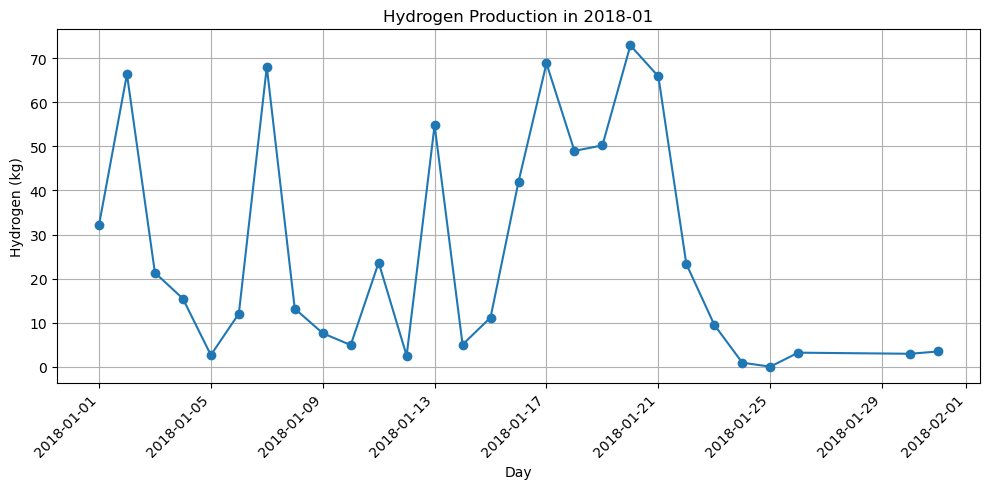

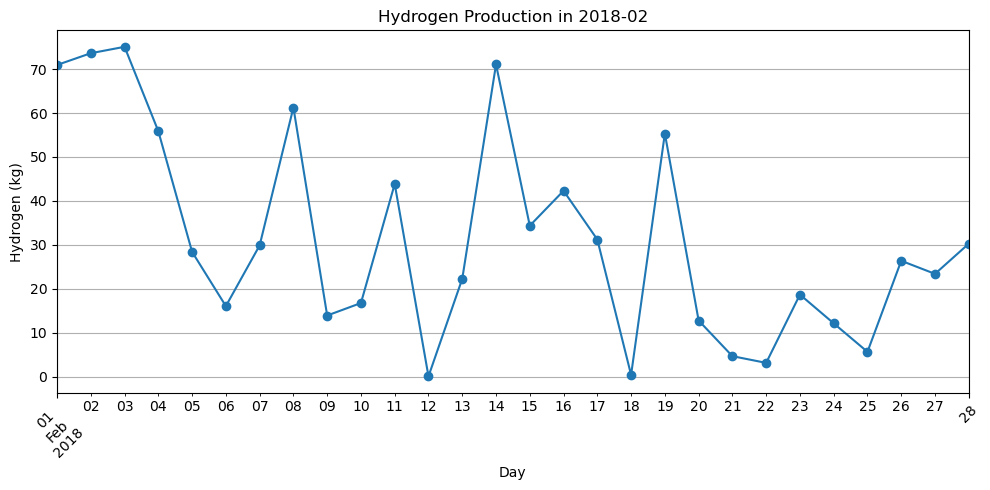

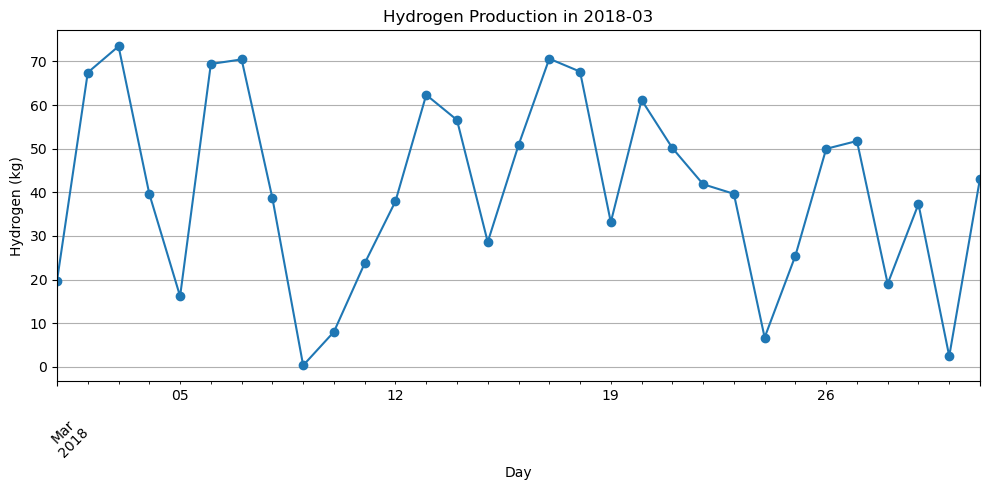

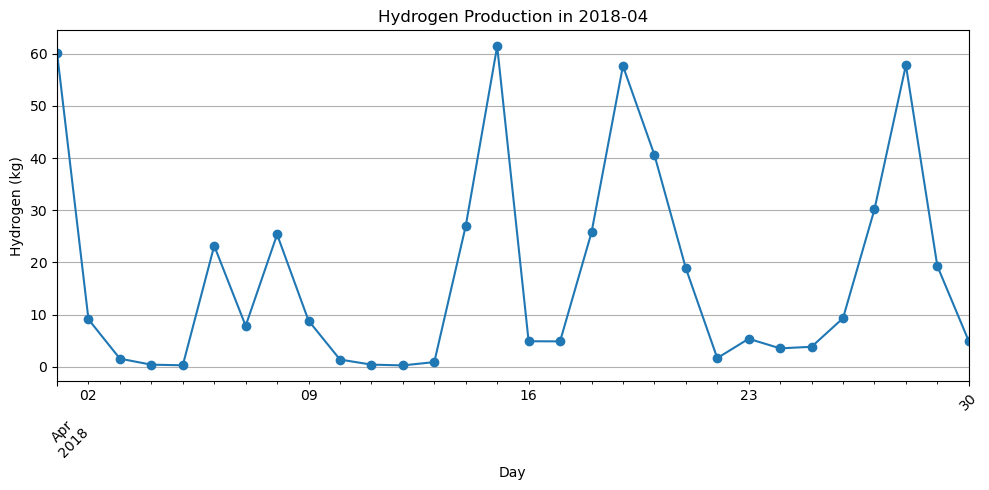

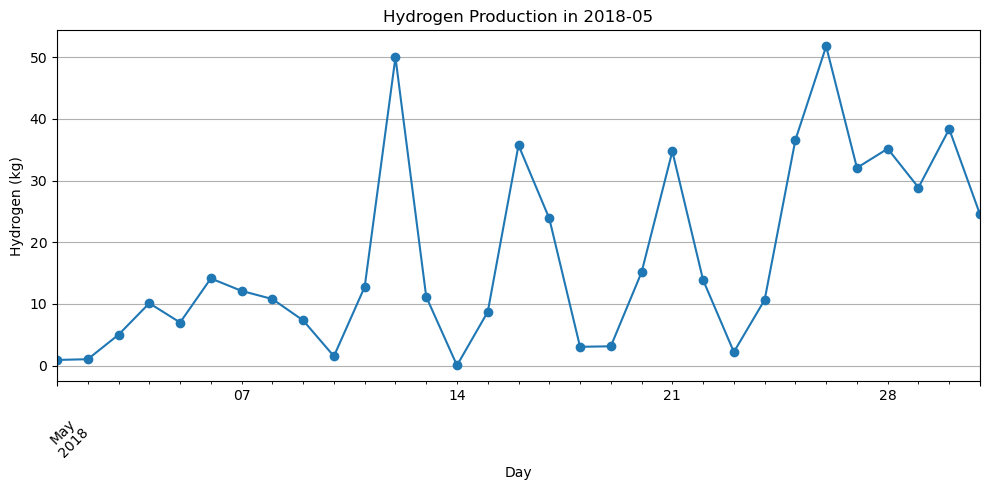

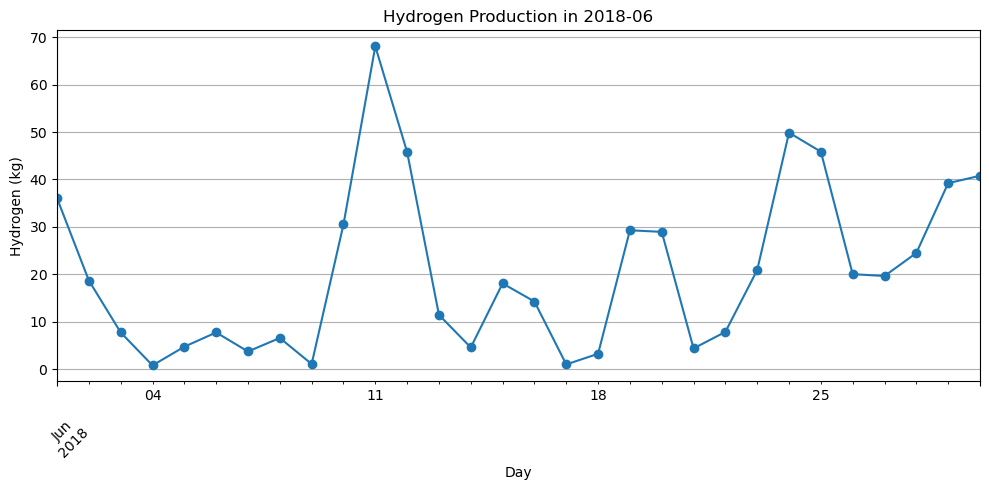

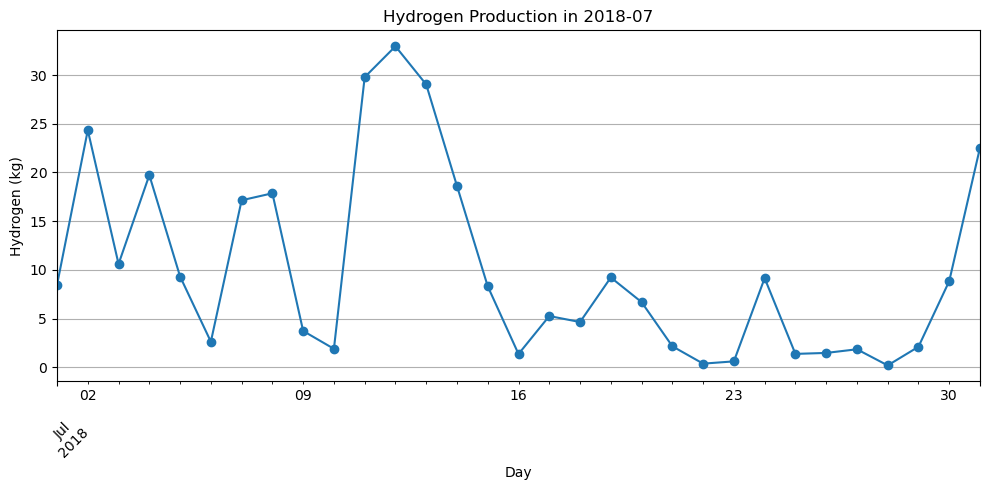

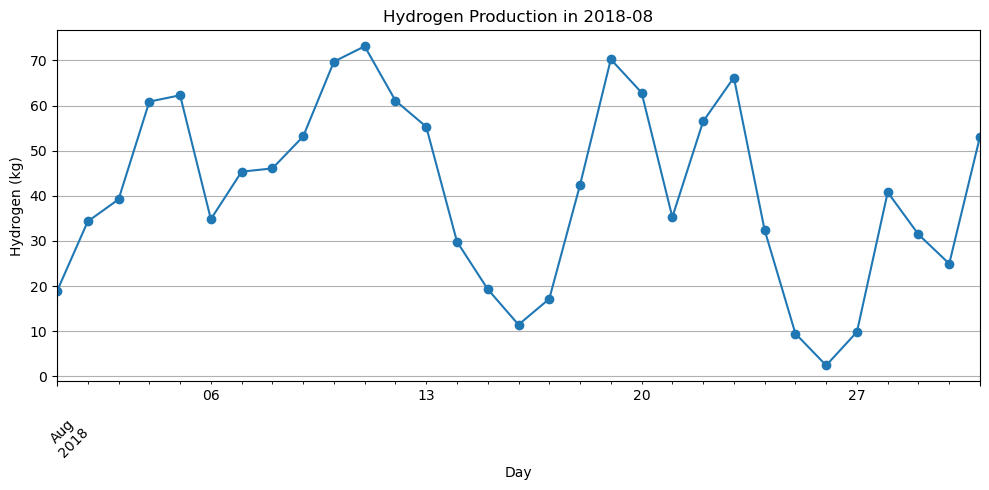

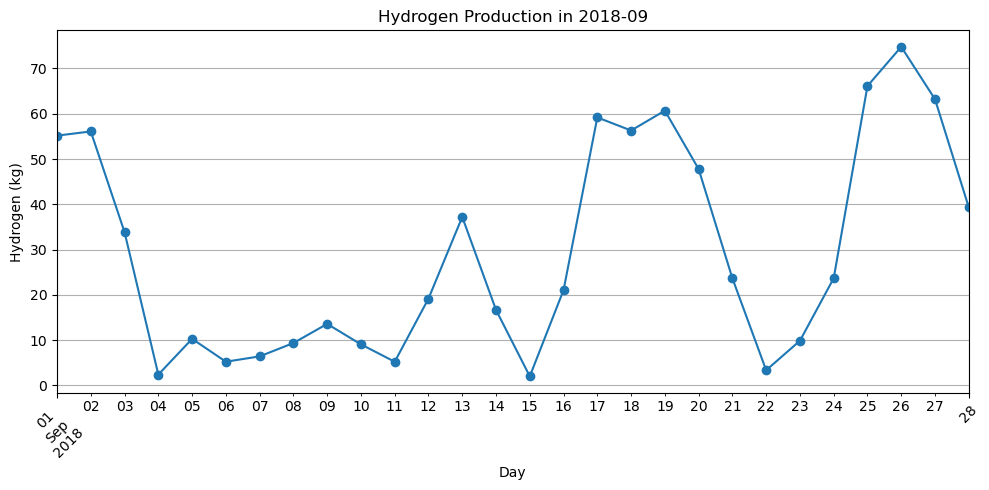

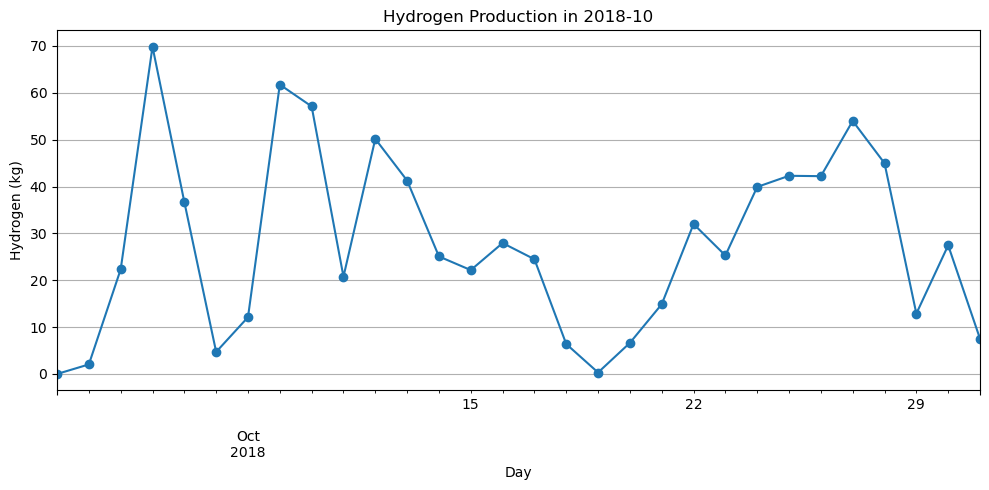

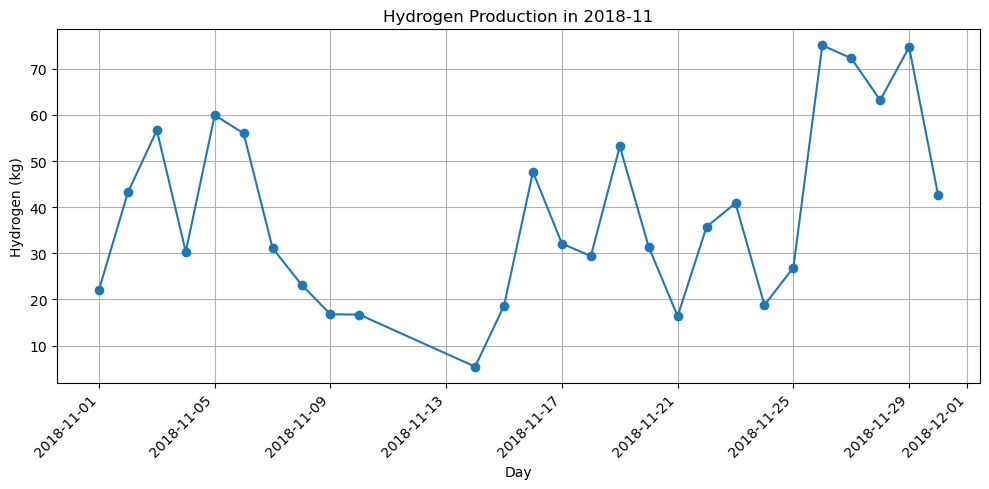

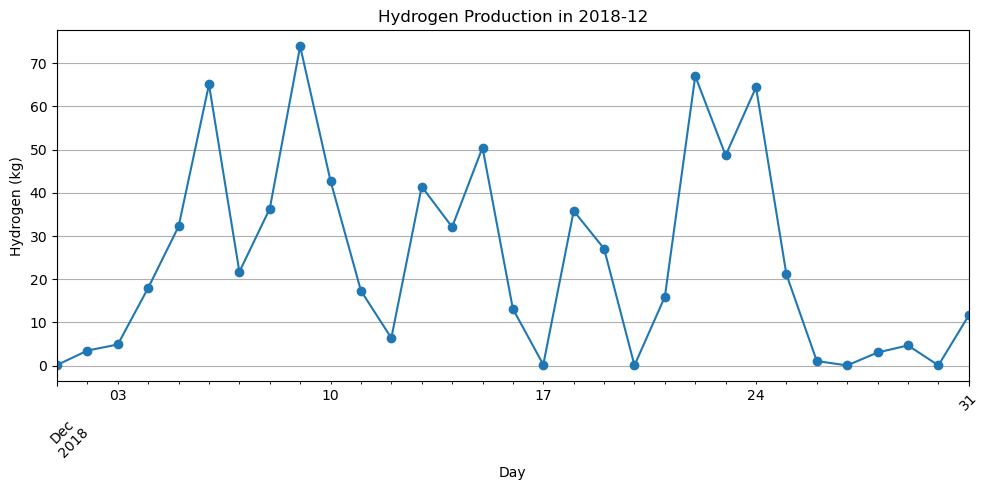

In [37]:
for month_period, group in daily_hydrogen.groupby('YearMonth'):
        plt.figure(figsize=(10, 5))
        group['Total Hydrogen (kg)'].plot(kind='line', marker='o')
        plt.title(f'Hydrogen Production in {month_period}')
        plt.xlabel('Day')
        plt.ylabel('Hydrogen (kg)')
        plt.grid(True)
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

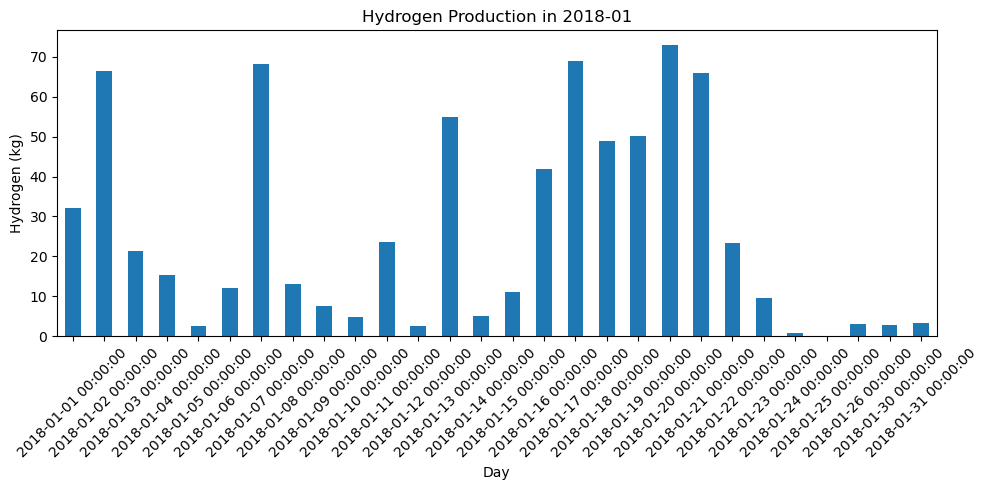

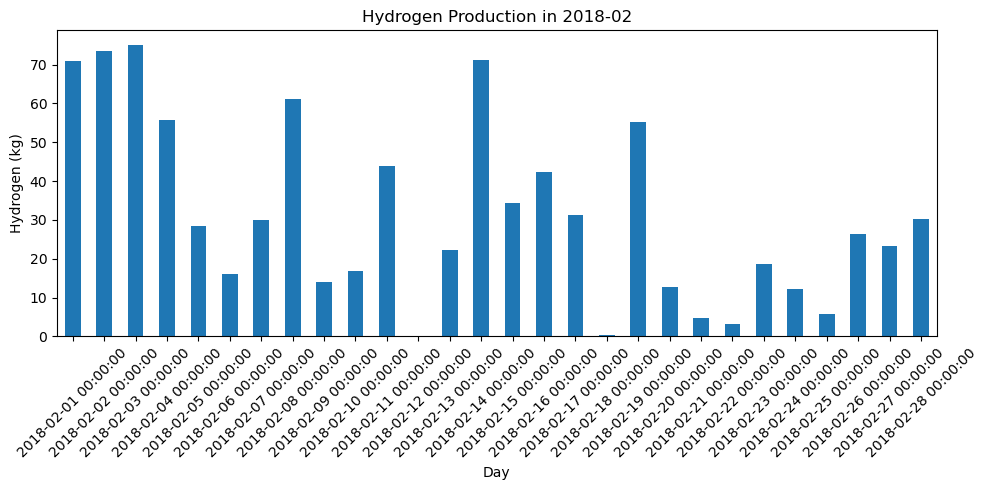

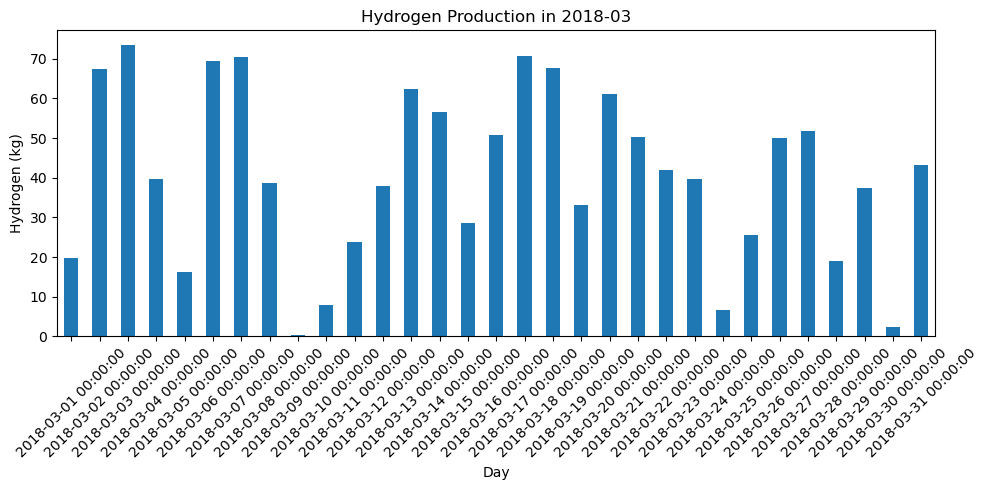

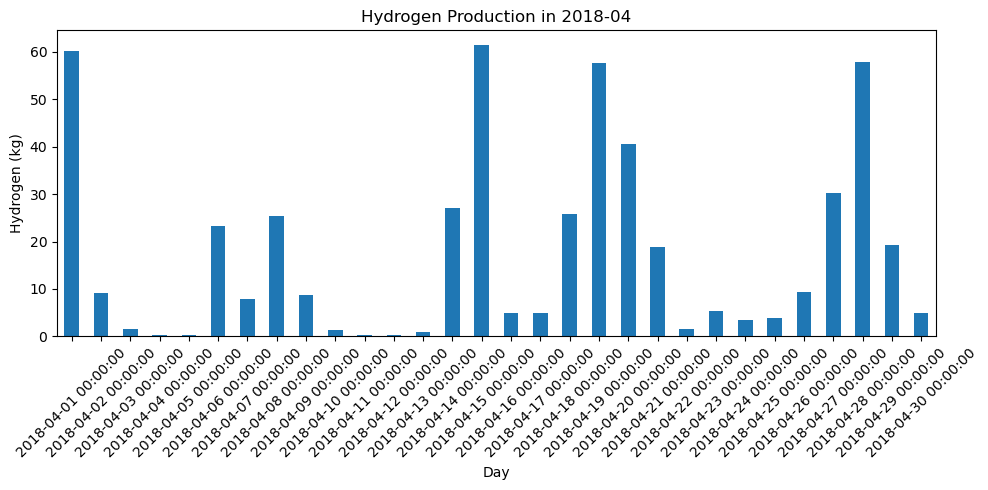

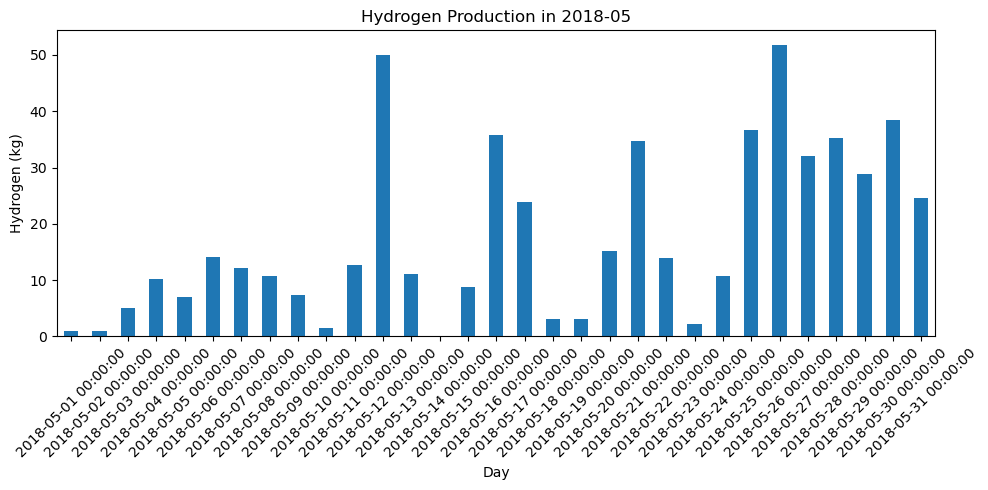

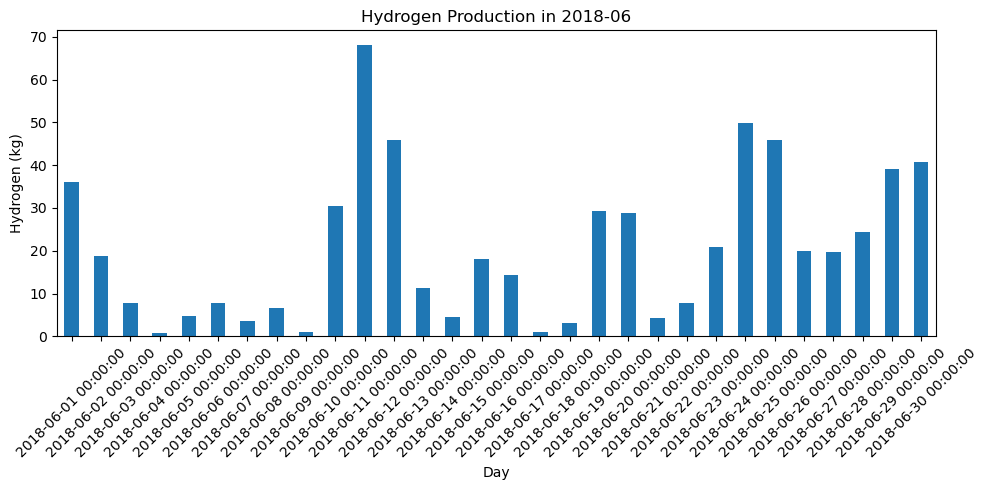

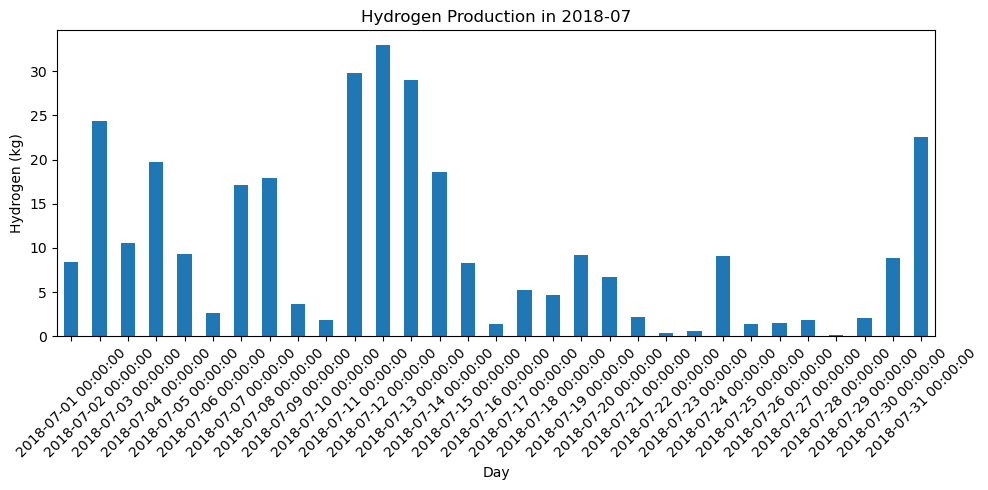

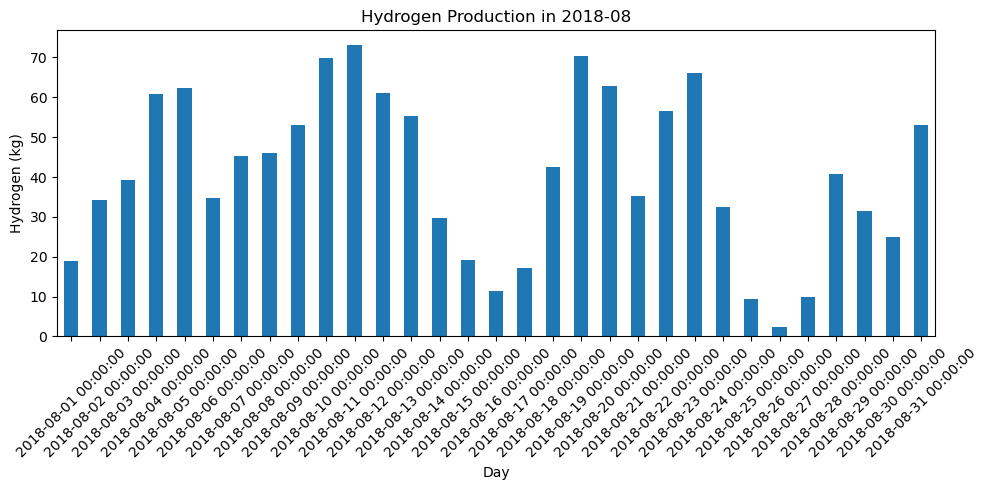

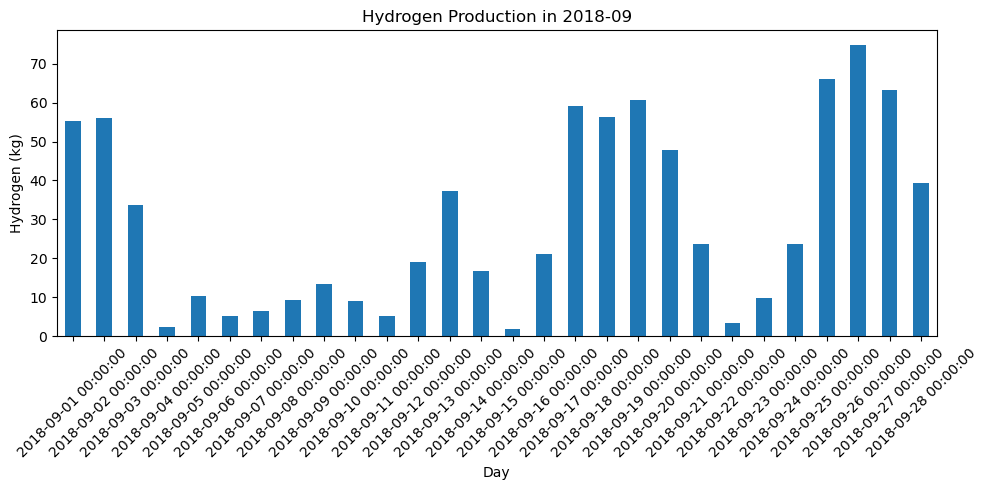

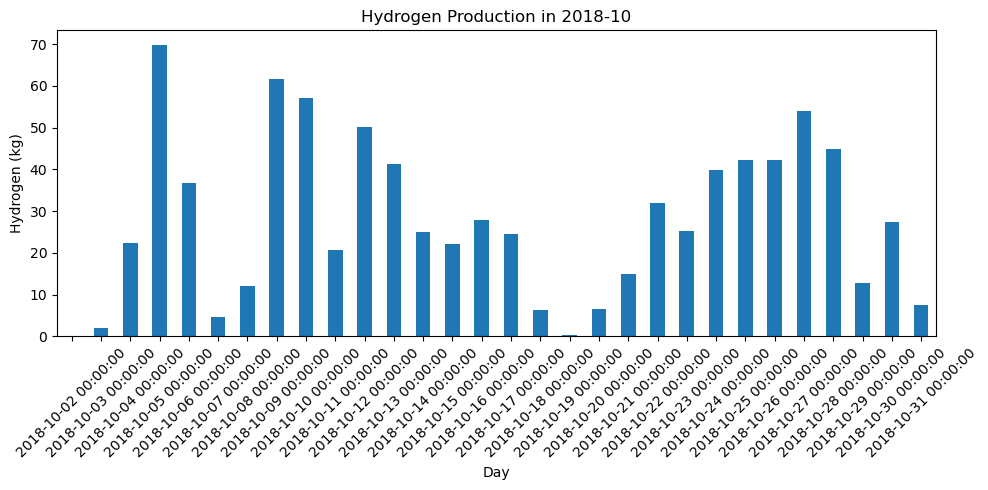

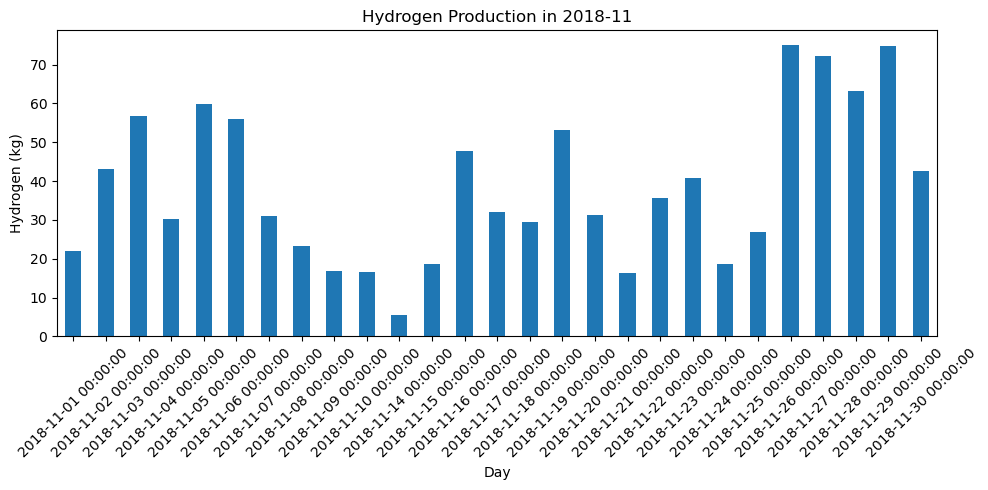

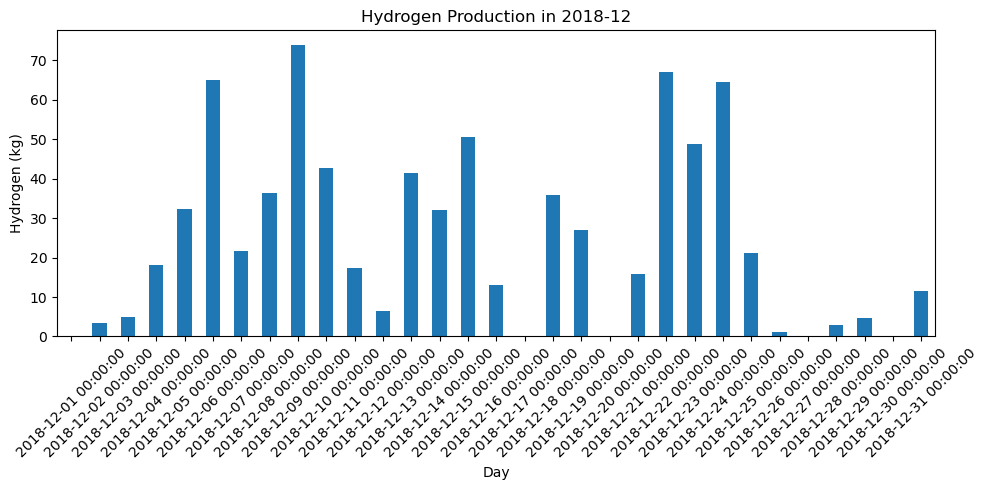

In [38]:
for month_period, group in daily_hydrogen.groupby('YearMonth'):
        plt.figure(figsize=(10, 5))
        group['Total Hydrogen (kg)'].plot(kind='bar')
        plt.title(f'Hydrogen Production in {month_period}')
        plt.xlabel('Day')
        plt.ylabel('Hydrogen (kg)')
        plt.grid(False)
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

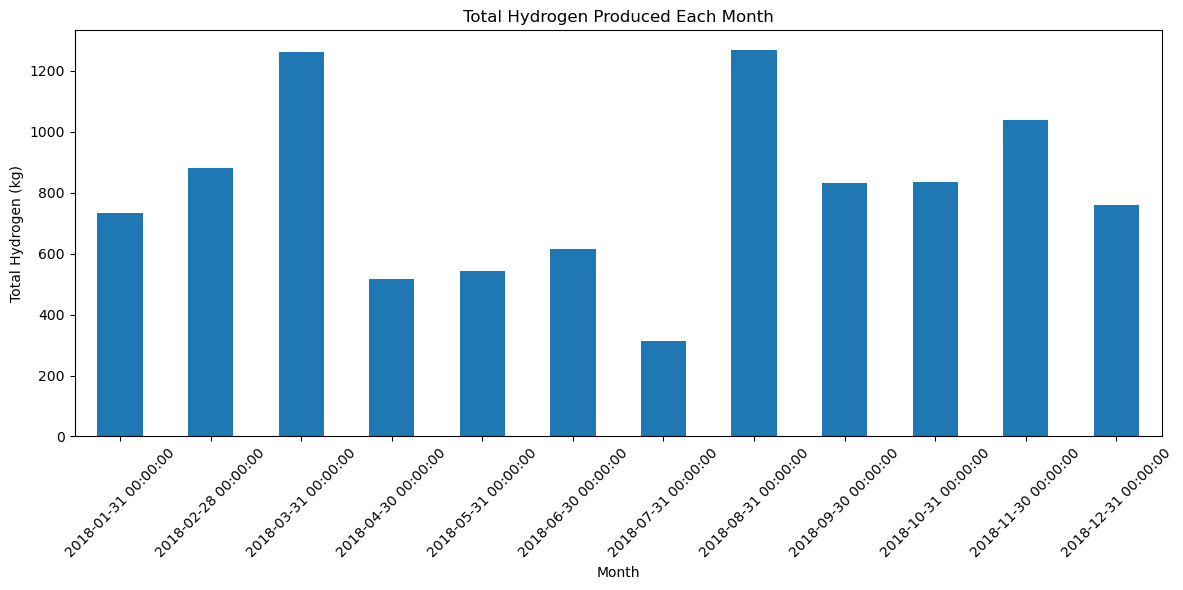

In [39]:
# Resample and sum hydrogen production by month
monthly_hydrogen_production = daily_hydrogen['Total Hydrogen (kg)'].resample('M').sum()

# Plotting
plt.figure(figsize=(12, 6))
monthly_hydrogen_production.plot(kind='bar')
plt.title('Total Hydrogen Produced Each Month')
plt.xlabel('Month')
plt.ylabel('Total Hydrogen (kg)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [40]:
# Resample and sum hydrogen production by month
monthly_hydrogen_production_1 = daily_hydrogen['Total Hydrogen (kg)'].resample('M').sum()

monthly_production_1 = pd.DataFrame(monthly_hydrogen_production_1)
new_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_production_1['Months'] = new_labels
monthly_production_1.head()

,Total Hydrogen (kg),Months
Date/Time,,
2018-01-31,733.310414,Jan
2018-02-28,879.755170,Feb
2018-03-31,1263.634558,Mar
2018-04-30,516.548919,Apr
2018-05-31,542.485190,May


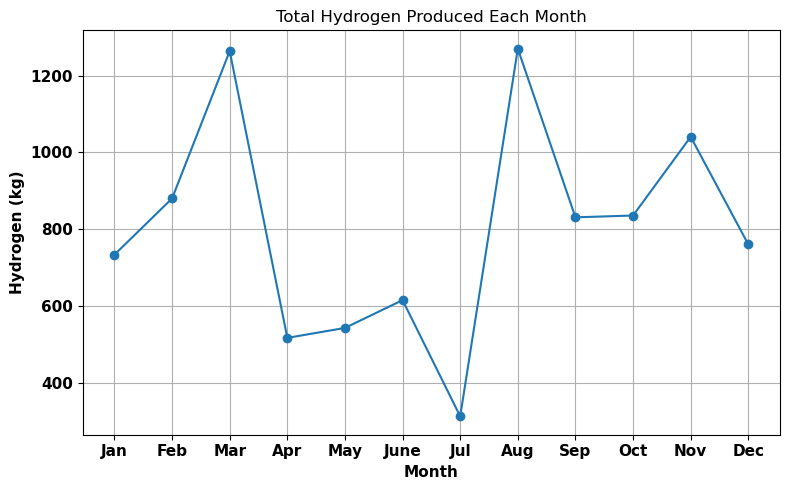

In [41]:
#plot scatter plot with lines


# Plotting
new_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

plt.figure(figsize=(8, 5))
plt.plot(monthly_production_1['Months'], monthly_production_1['Total Hydrogen (kg)'] , marker='o')

plt.title('Total Hydrogen Produced Each Month')
plt.xlabel('Month', fontweight='bold', fontsize=11)
plt.ylabel('Hydrogen (kg)', fontweight='bold', fontsize=11)
# original_ticks = graph.get_xticks()
# plt.xticks(ticks = original_ticks, labels=new_labels, fontweight='bold', fontsize=11)
plt.xticks(fontweight='bold', fontsize=11)
plt.yticks(fontweight='bold', fontsize=11)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# sum hydrogen for one day

Now sum the hydrogen produced every month, and total hydrogen produced over the year

In [42]:
# Sum the hydrogen produced every month
monthly_hydrogen_sum = daily_hydrogen['Total Hydrogen (kg)'].resample('M').sum()

# The result is a Series where the index is the month and the values are the total hydrogen produced in that month
print(monthly_hydrogen_sum)

Date/Time
2018-01-31     733.310414
2018-02-28     879.755170
2018-03-31    1263.634558
2018-04-30     516.548919
2018-05-31     542.485190
2018-06-30     614.869888
2018-07-31     312.155620
2018-08-31    1269.810205
2018-09-30     830.550937
2018-10-31     835.315995
2018-11-30    1040.284561
2018-12-31     760.013226
Freq: M, Name: Total Hydrogen (kg), dtype: float64


In [43]:
# Sum the hydrogen produced every year
yearly_hydrogen_sum = daily_hydrogen['Total Hydrogen (kg)'].resample('Y').sum()

# The result is a Series where the index is the year and the values are the total hydrogen produced in that year
print(yearly_hydrogen_sum)

Date/Time
2018-12-31    9598.734682
Freq: A-DEC, Name: Total Hydrogen (kg), dtype: float64
